# Mexico's yield curve: pattern, forecasts and the value of the pattern

**Author:** Alejandro Muñoz Fernández

This notebook reproduces every number, table and figure in the brief (rendimiento_bonos_brief.pdf) from the raw auction data. It is organized in five steps, and it ends with a traceability table that compares each figure quoted in the brief with the value computed here.

**Data:** monthly average primary-auction rates for nine Mexican government instruments, CETES at 28, 91, 182 and 364 days and BONOS M at 3, 5, 10, 20 and 30 years, October 2006 to September 2026 (Banco de México). External series (Banxico policy rate, US Treasury yields, Mexican inflation) are embedded in `external_data.py`, survey expectations in `survey_data.py` and market variables (EMBIG spread, peso per dollar, foreign holdings of BONOS M) in `market_data.py`, each with its source.

**The three questions and the short answers**
1. *Is there a pattern in how the nine maturities move?* Yes: level, slope and curvature explain more than 90% of changes over three months or more.
2. *Can the curve be forecast one and four quarters ahead?* Yes for CETES one quarter ahead (12% to 35% less error than assuming no change); no for BONOS M, and not reliably one year ahead.
   One year ahead, CETES become forecastable once Banxico's survey of analysts is added (about 22% less error, in both halves of the sample).
3. *Does the pattern improve the forecasts?* Yes when the slope is used as a signal of Banxico's next moves; no when each movement is assumed to revert to its historical average.

Running the whole notebook takes about one minute. In Google Colab, choose *Runtime > Run all*: the first cell downloads the repository and nothing needs to be installed.

In [1]:
# Setup. In Google Colab this cell downloads the repository (about 10 MB, a few seconds); locally it does nothing.
import os, sys
REPO_URL = "https://github.com/alexmufe/rendimiento_bonos.git"
if not os.path.exists("data/banxico_auction_rates_monthly.csv"):
    if not os.path.exists("rendimiento_bonos"):
        os.system(f"git clone -q --depth 1 {REPO_URL}")
    os.chdir("rendimiento_bonos")
sys.path.insert(0, os.getcwd())

In [2]:
import io, contextlib
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option("display.precision", 3)

# Runs the full pipeline (about 25 seconds): data, pattern analysis, out-of-sample forecasts and tests.
with contextlib.redirect_stdout(io.StringIO()):
    import yield_curve as C      # tables and diagnostic figures in outputs/
    import events as E           # Banxico cycle, crisis treatment, pooled windows
    import surveys as S          # analysts' survey expectations (Banxico and Philadelphia Fed)
    import extra_predictors as X # market variables: EMBIG spread, exchange rate, foreign holdings, long slope
    import figures               # figures used in the brief
OUT = C.OUT
Y, raw, EXT, COLS = C.Y, C.raw, C.EXT, C.COLS
CETES, BONOS = COLS[:4], COLS[4:]
print("Months:", len(raw), "| maturities:", COLS)

Months: 240 | maturities: ['1m', '3m', '6m', '12m', '3y', '5y', '10y', '20y', '30y']


## 1. Check the data

**Decision:** correct the file against Banxico's official weekly auctions (SIE table CF107) and fill gaps only for estimation, never for scoring forecasts.

The comparison found three issues: the 364-day CETE is slightly higher than the official figure in 125 months, the auction of 31 March 2021 is missing from the March averages, and two July 2010 bond auctions are missing. The cell below counts the cells the correction changes and the gaps by maturity.

In [3]:
df = pd.read_csv("data/banxico_auction_rates_monthly.csv", parse_dates=["DATE"])
orig = df.pivot_table(index="DATE", columns="INSTRUMENT", values="VALUE_PCT")[C.ORDER]
orig.columns = COLS; orig = orig.asfreq("MS")
changed = (orig.fillna(-99).round(4) != raw.fillna(-99).round(4))
print("Rows in the file:", len(df), "| cells changed by the correction:", int(changed.values.sum()))
print(changed.sum().rename("cells changed").to_frame().T)
miss = raw.isna().sum()
print("\nMissing months by maturity (out of 240):"); print(miss.to_frame("missing").T)
print("Months with all nine rates:", int(raw.notna().all(axis=1).sum()))
print("Share of months missing, 10y/20y/30y: ", (miss[["10y", "20y", "30y"]] / len(raw)).round(2).to_dict())

Rows in the file: 1936 | cells changed by the correction: 130
               1m  3m  6m  12m  3y  5y  10y  20y  30y
cells changed   0   1   1  125   1   0    0    1    1

Missing months by maturity (out of 240):
         1m  3m  6m  12m  3y  5y  10y  20y  30y
missing   0   0   0    0   4  16   63   68   71
Months with all nine rates: 40
Share of months missing, 10y/20y/30y:  {'10y': 0.26, '20y': 0.28, '30y': 0.3}


## 2. Find the pattern (Question 1)

**Decision:** run principal components on rate *changes* (levels share a long-term trend that inflates the first component), and report changes over 1, 3 and 12 months.

In [4]:
print("Share of variance explained (principal components on changes):")
display(pd.read_csv(f"{OUT}/t1_pca_by_horizon.csv"))
v_lv = C.pca(Y.values)[0]
print(f"For contrast, components on levels: first component = {v_lv[0]:.0%}")
d12 = Y.diff(12).dropna()
a, b = C.pca(d12.loc[:"2015-12"].values)[0], C.pca(d12.loc["2016-01":].values)[0]
print(f"Half samples, 12-month changes: 2006-2015 level {a[0]:.1%}, slope {a[1]:.1%} | 2016-2026 level {b[0]:.1%}, slope {b[1]:.1%}")

Share of variance explained (principal components on changes):


,horizon_months,PC1,PC2,PC3,cum3
0,1,0.518,0.166,0.095,0.779
1,3,0.652,0.219,0.043,0.914
2,12,0.864,0.102,0.020,0.986


For contrast, components on levels: first component = 94%
Half samples, 12-month changes: 2006-2015 level 62.5%, slope 30.3% | 2016-2026 level 90.9%, slope 7.0%


**Figure 2.** Weight of each maturity in the three movements (one-year changes).

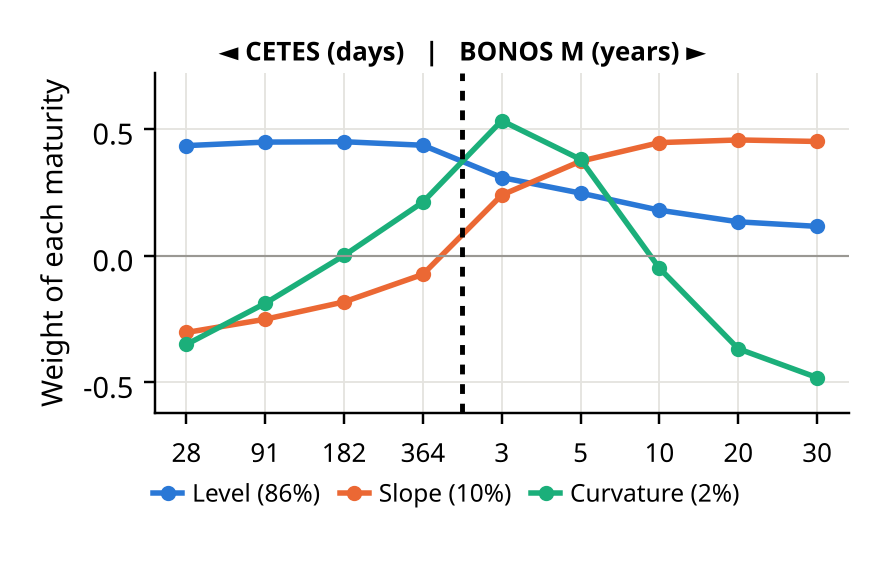

In [5]:
display(Image(f"{OUT}/fig2_movements.png", width=520))

**Five-year periods (Table 1 of the brief).** The level share comes from principal components on 12-month changes within each period. The slope column correlates the Nelson-Siegel slope (long minus short) with Banxico's policy rate, both in levels. The US column correlates 12-month changes in the Nelson-Siegel level with 12-month changes in the 10-year Treasury yield.

In [6]:
NS = C.ns_factors(raw, C.OBS, C.LAM_DL)
slope_ns, level_ns = -NS["S"], NS["L"]
rows = []
for a_, b_ in [("2007", "2011"), ("2012", "2016"), ("2017", "2021"), ("2022", "2026")]:
    rows.append({"period": f"{a_}-{b_}",
                 "level share": C.pca(d12.loc[a_:b_].values)[0][0],
                 "corr(slope, Banxico rate)": slope_ns.loc[a_:b_].corr(EXT.policy_rate.loc[a_:b_]),
                 "corr(level, US 10y), 12m changes": level_ns.diff(12).loc[a_:b_].corr(EXT.ust10.diff(12).loc[a_:b_])})
PERIODS = pd.DataFrame(rows).set_index("period"); PERIODS.round(2)

,level share,"corr(slope, Banxico rate)","corr(level, US 10y), 12m changes"
period,,,
2007-2011,0.77,-0.92,-0.10
2012-2016,0.51,-0.82,0.71
2017-2021,0.91,-0.91,0.66
2022-2026,0.93,-0.94,0.46


**Outliers, inverted curve and curvature.** Extreme months are measured on the monthly change of the Nelson-Siegel level.

In [7]:
dL = level_ns.diff().abs().dropna()
print(f"Typical monthly change of the level (median): {dL.median():.2f} points; 95th percentile: {dL.quantile(.95):.2f}")
print("Months with a level change above 1.1 points:", [f"{d:%b-%Y}" for d in dL[dL > 1.1].index])
sd = level_ns.diff().groupby(level_ns.index.year).std()
calm = sd.loc[[2006, 2007, 2025]]
print(f"Volatility in 2009 and 2020 versus the three calmest years: {sd[2009]/calm.max():.1f}x to {sd[2009]/calm.min():.1f}x (2009), "
      f"{sd[2020]/calm.max():.1f}x to {sd[2020]/calm.min():.1f}x (2020)")
inv = slope_ns < 0
print(f"Months with a negative fitted slope (short rates above long rates): {int(inv.sum())}; minimum {slope_ns.min():.1f} in {slope_ns.idxmin():%b-%Y}")
j = d12["3y"].idxmax()
print(f"Largest 12-month rise of the 3-year bond: {d12.loc[j, '3y']:.2f} points to {j:%b-%Y} (28-day CETE {d12.loc[j, '1m']:.2f}, 30-year bond {d12.loc[j, '30y']:.2f})")

Typical monthly change of the level (median): 0.20 points; 95th percentile: 0.73
Months with a level change above 1.1 points: ['Oct-2008', 'Feb-2009', 'Jun-2013', 'Mar-2020']
Volatility in 2009 and 2020 versus the three calmest years: 3.5x to 4.8x (2009), 3.3x to 4.5x (2020)
Months with a negative fitted slope (short rates above long rates): 43; minimum -3.4 in Apr-2023
Largest 12-month rise of the 3-year bond: 3.85 points to Mar-2022 (28-day CETE 2.26, 30-year bond 0.92)


**Figure 1.** Twenty years of the curve, with events.

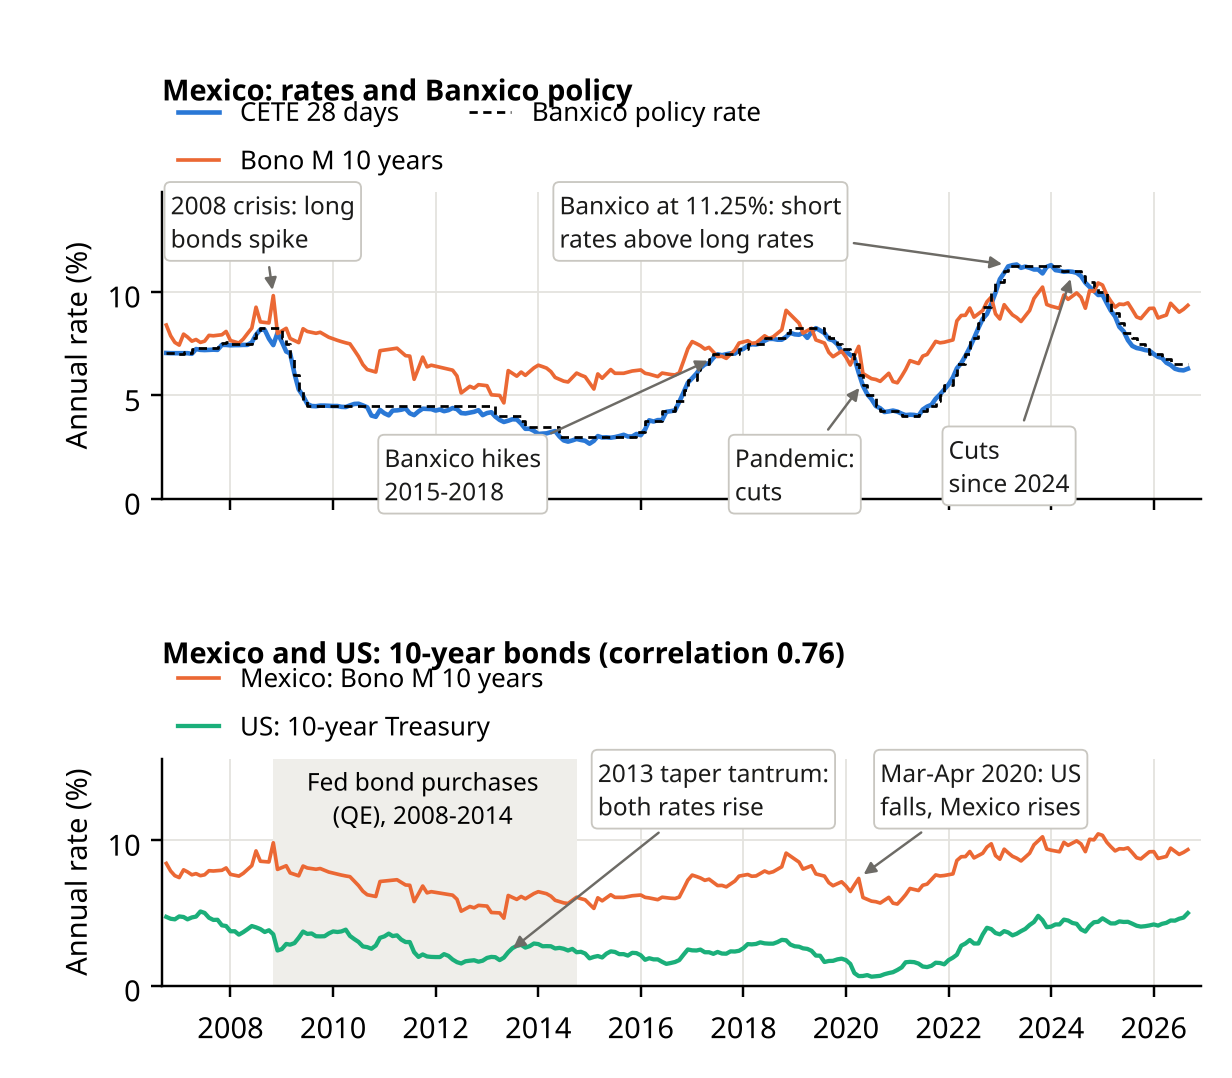

In [8]:
display(Image(f"{OUT}/fig1_curve_events.png", width=620))

## 3. Test forecasts (Question 2)

**Decisions:** forecast the rate 3 and 12 months later with direct regressions; in each month from December 2012, estimate every model only with data available that month (expanding window); score only against months with an actual auction; compare every model with the random walk ("the rate does not change") using root mean squared error and the Diebold-Mariano test with the Harvey-Leybourne-Newbold correction.

In [9]:
R = pd.read_csv(f"{OUT}/t2_forecasts_long.csv", parse_dates=["origin", "target"])
print("Forecast origins:", R.origin.nunique(), f"({R.origin.min():%b-%Y} to {R.origin.max():%b-%Y})")
SEG = {"CETES": CETES, "BONOS M": BONOS, "Curve": COLS}
def seg_ratio(m, h, pls, base="RW"):
    mm = C.paired(R.rename(columns={"model": "model"}), m, base, h)
    mm = mm[mm.maturity.isin(pls)]
    r = np.sqrt((mm.err_1**2).mean() / (mm.err_2**2).mean()); _, p = C.dm_hln(mm.err_1.values, mm.err_2.values, h)
    return r, p
models = [("AR1", "Each rate's history (AR)"), ("Slope", "No change + CETES slope"), ("VAR1", "All nine rates (VAR)"),
          ("DNS-VAR1", "Three movements + VAR (Nelson-Siegel)"), ("DNS-AR1", "Three movements + AR (Diebold-Li)"),
          ("PCA3-AR1", "Three movements + AR (principal components)")]
rows = []
for m, lab in models:
    row = {"model": lab}
    for h in [3, 12]:
        for s, pls in SEG.items():
            r, p = seg_ratio(m, h, pls); row[f"h={h} {s}"] = f"{r:.2f}" + ("*" if p < .05 else "")
    rows.append(row)
TABLE2 = pd.DataFrame(rows).set_index("model")
print("Table 2. RMSE relative to 'the rate does not change' (* = significant at 95%, Diebold-Mariano HLN)")
TABLE2

Forecast origins: 163 (Dec-2012 to Jun-2026)


Table 2. RMSE relative to 'the rate does not change' (* = significant at 95%, Diebold-Mariano HLN)


,h=3 CETES,h=3 BONOS M,h=3 Curve,h=12 CETES,h=12 BONOS M,h=12 Curve
model,,,,,,
Each rate's history (AR),1.04*,1.02,1.03*,1.05,1.05,1.05
No change + CETES slope,0.75*,1.04*,0.91*,0.88,1.12*,0.95
All nine rates (VAR),0.72*,1.02,0.88*,0.89,1.11*,0.95
Three movements + VAR (Nelson-Siegel),0.90*,0.99,0.94*,0.96,1.06,0.99
Three movements + AR (Diebold-Li),1.21*,1.03,1.12*,1.14,1.10,1.13*
Three movements + AR (principal components),1.13*,1.42*,1.28*,1.04,1.12*,1.06


**Figure 3.** Slope model versus no change, by maturity and horizon.

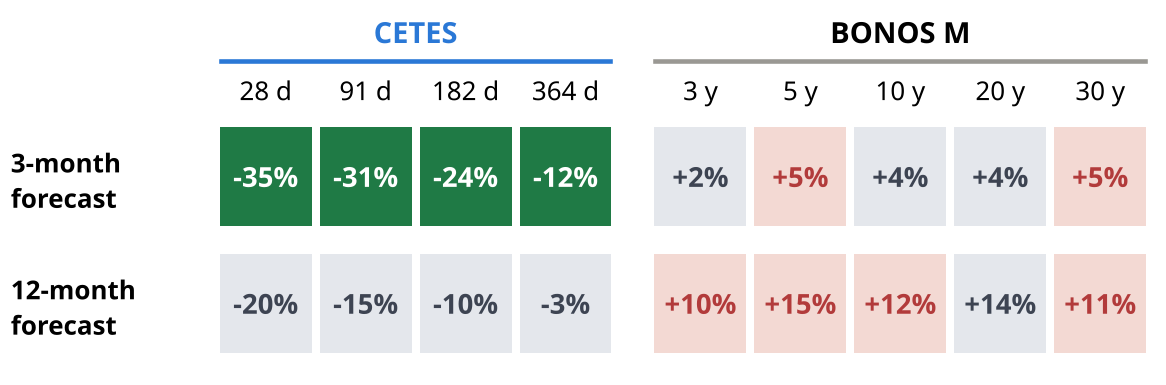

In [10]:
display(Image(f"{OUT}/fig3_error_grid.png", width=620))

In [11]:
ratio = pd.read_csv(f"{OUT}/t3_rmse_ratio_vs_RW.csv").set_index(["h", "model"])
print("Slope model, change in error vs no change, CETES at 3 months:", ((ratio.loc[(3, "Slope"), CETES] - 1) * 100).round(0).to_dict())
# Subperiods, CETES at 12 months
# Subperiods are split by forecast date (origin): 2013-2019 versus 2020-2026
c12 = R[(R.h == 12) & R.maturity.isin(CETES)].copy(); c12["sub"] = np.where(c12.origin < "2020-01-01", "2013-2019", "2020-2026")
SUBP = {}
for sname, g in c12.groupby("sub"):
    e = lambda m: np.sqrt((g[g.model == m].err**2).mean())
    SUBP[sname] = e('Slope')/e('RW') - 1; print(f"CETES at 12 months, forecasts made in {sname}: slope model vs no change {SUBP[sname]:+.0%}")

Slope model, change in error vs no change, CETES at 3 months: {'1m': -35.0, '3m': -31.0, '6m': -24.0, '12m': -12.0}
CETES at 12 months, forecasts made in 2013-2019: slope model vs no change +6%
CETES at 12 months, forecasts made in 2020-2026: slope model vs no change -22%


**Where the gain comes from (Figure 4).** Forecast windows are classified by how much Banxico moved its policy rate between the forecast date and the target month. A "change of direction" is shown under two definitions, because the result depends on it.

Banxico moved more than 0.5 points in the window: -35%
Banxico held its rate:                          +46%
Change of direction (window move opposite to previous 6 months): -18%
Change of direction (cycle indicator differs, target non-zero):  -18%


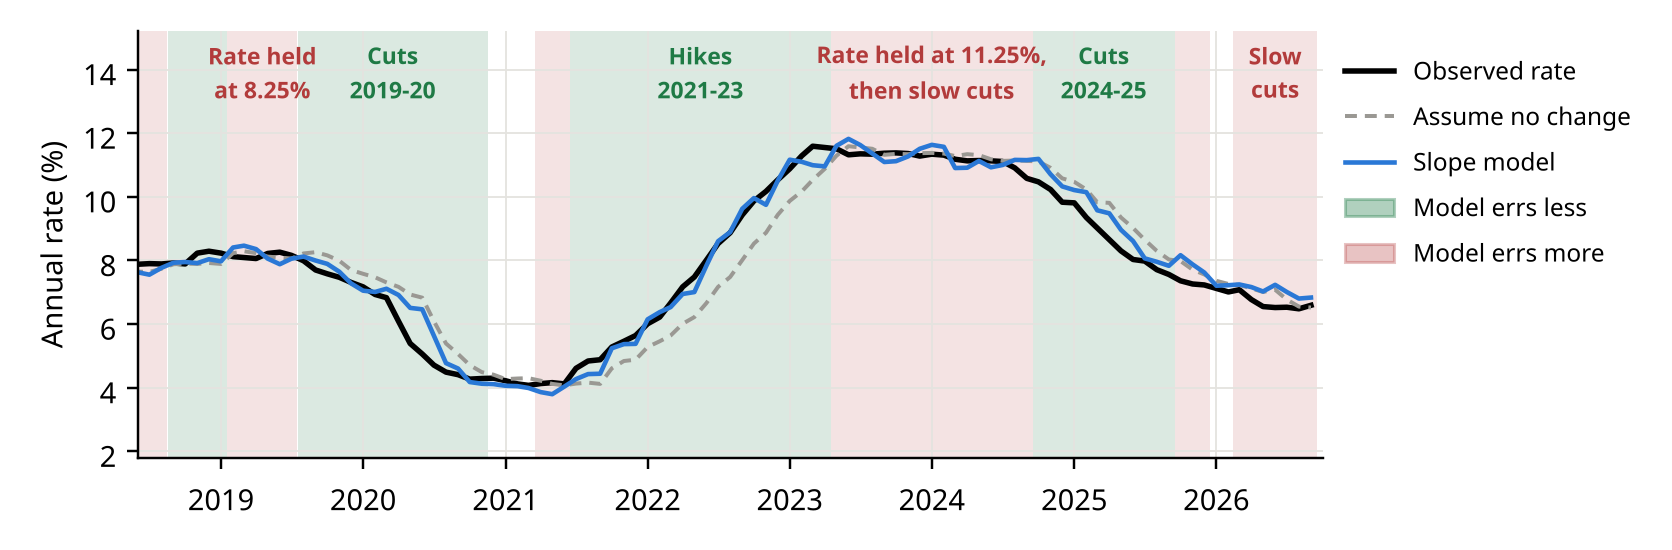

In [12]:
c3 = R[(R.h == 3) & R.maturity.isin(CETES)].copy()
pol = EXT.policy_rate
c3["dpol"] = [pol.asof(t) - pol.asof(o) for o, t in zip(c3.origin, c3.target)]
c3["dprev"] = [pol.asof(o) - pol.asof(o - pd.DateOffset(months=6)) for o in c3.origin]
c3["cyc_o"] = [E.CYCLE.asof(o) for o in c3.origin]; c3["cyc_t"] = [E.CYCLE.asof(t) for t in c3.target]
def gain(g):
    e = lambda m: np.sqrt((g[g.model == m].err**2).mean()); return e("Slope") / e("RW") - 1
print(f"Banxico moved more than 0.5 points in the window: {gain(c3[c3.dpol.abs() > .5]):+.0%}")
print(f"Banxico held its rate:                          {gain(c3[c3.dpol == 0]):+.0%}")
print(f"Change of direction (window move opposite to previous 6 months): {gain(c3[np.sign(c3.dpol) * np.sign(c3.dprev) < 0]):+.0%}")
print(f"Change of direction (cycle indicator differs, target non-zero):  {gain(c3[(c3.cyc_o != c3.cyc_t) & (c3.cyc_t != 0)]):+.0%}")
display(Image(f"{OUT}/fig4_cete91_forecast.png", width=560))

## 4. Measure the value of the pattern (Question 3)

**Decision:** compare each model that uses the pattern with an equivalent model that does not, over the same months (whole curve).

In [13]:
Q3 = C.Q3.copy()   # unrounded version of outputs/t3_pattern_vs_no_pattern.csv
Q3["change in error"] = (Q3.RMSE_ratio - 1).map(lambda x: f"{x:+.0%}")
Q3["significant (95%)"] = Q3.p < .05
Q3[["h", "with_pattern", "without_pattern", "change in error", "significant (95%)"]]

,h,with_pattern,without_pattern,change in error,significant (95%)
0,3,Slope,AR1,-12%,True
1,3,DNS-VAR1,AR1,-8%,True
2,3,VAR1,AR1,-14%,True
3,3,DNS-AR1,AR1,+9%,True
4,3,PCA3-AR1,AR1,+24%,True
5,3,DNS-VAR1,VAR1,+7%,True
6,3,PCA3-VAR1,VAR1,+44%,True
7,3,Slope,VAR1,+3%,False
8,12,Slope,AR1,-10%,True
9,12,DNS-VAR1,AR1,-6%,False


Banxico policy rate, full-sample average: 6.3%
2015 max 3.25 min 3.0
2018 max 8.25 min 7.25
2021 max 5.5 min 4.0
2023 max 11.25 min 10.5


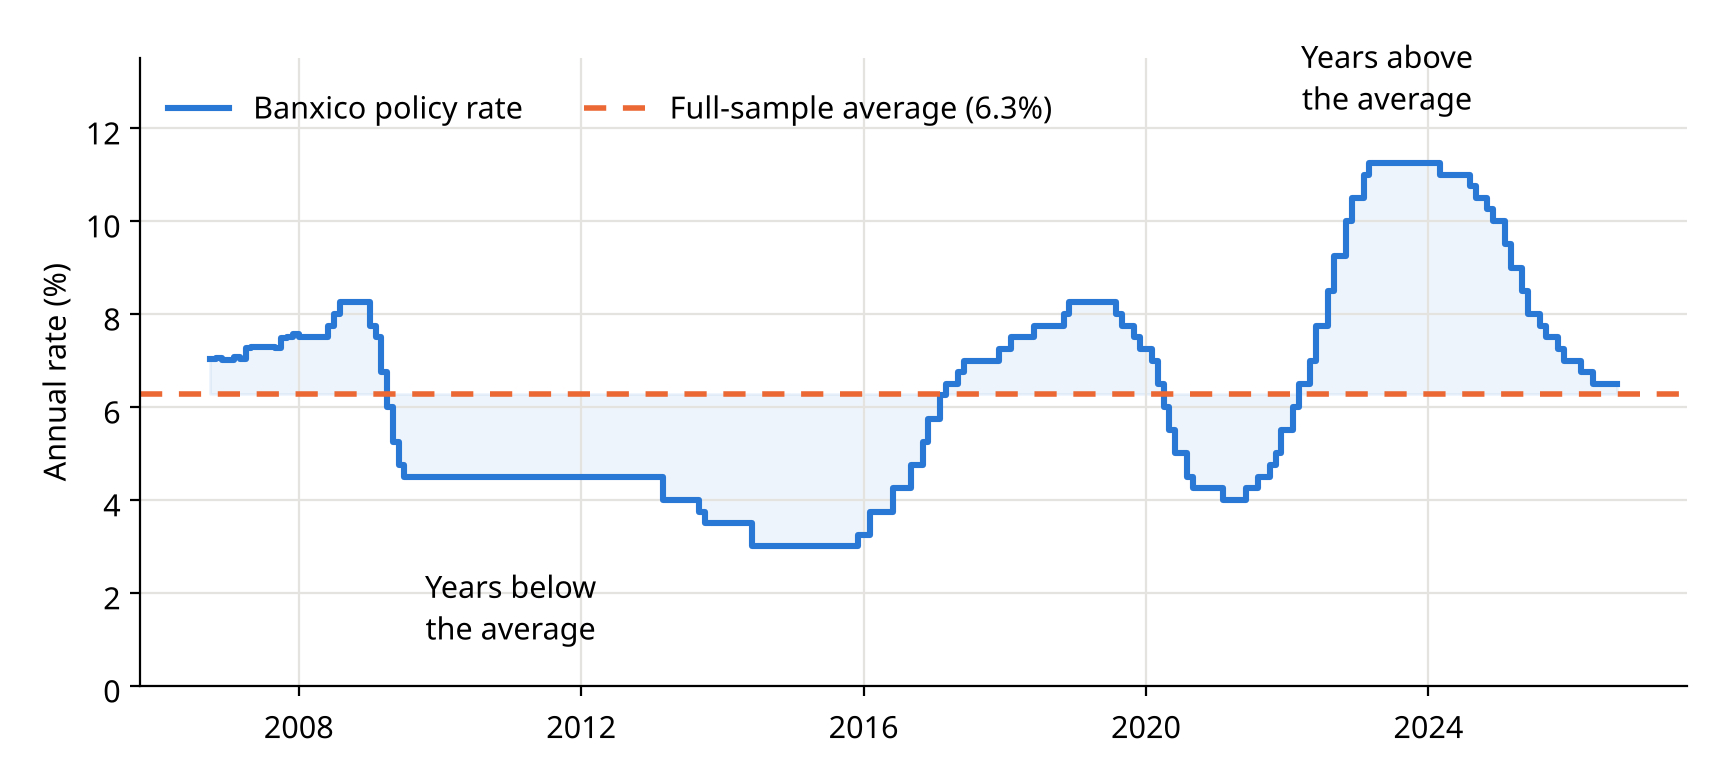

In [14]:
r = EXT.policy_rate.loc["2006-10":]
print(f"Banxico policy rate, full-sample average: {r.mean():.1f}%")
for y in [2015, 2018, 2021, 2023]: print(y, "max", r.loc[str(y)].max(), "min", r.loc[str(y)].min())
display(Image(f"{OUT}/slide_policy_rate_vs_average.png", width=560))

## 5. Test additional information

**Decision:** use each external data point only once it was public (policy rate at month end, inflation with a one-month lag), and compare every variant with the slope model.

In [15]:
T4, T5 = C.EXTT, E.T   # unrounded versions of outputs/t4_external_data.csv and outputs/t5_events.csv
show = pd.concat([T4[T4.segment != "Curve"][["h", "model", "segment", "RMSE_vs_Slope", "p"]].rename(columns={"p": "p_vs_Slope"}),
                  T5[(T5.segment != "Curve") & (T5.excl_pandemic == False) & T5.RMSE_vs_Slope.notna()][["h", "model", "segment", "RMSE_vs_Slope", "p_vs_Slope"]]])
show["change vs slope"] = (show.RMSE_vs_Slope - 1).map(lambda x: f"{x:+.0%}")
show.pivot_table(index="model", columns=["segment", "h"], values="change vs slope", aggfunc="first")

segment              BONOS       CETES      
h                       3     12    3     12
model                                       
Ext:Policy             -0%   +1%  +20%  +11%
Ext:Slope+RealRate     +1%   +3%   +1%  -10%
Ext:Slope+SpreadUST    +2%  +13%   +4%  +10%
Ext:Slope+ΔUST         +1%   +0%   +1%   +0%
Slope excl. episodes   +0%   +5%   +8%   +4%
Slope pooled windows   -1%   +0%   -0%   +1%
Slope+Cycle            +4%   +6%   -1%  +10%

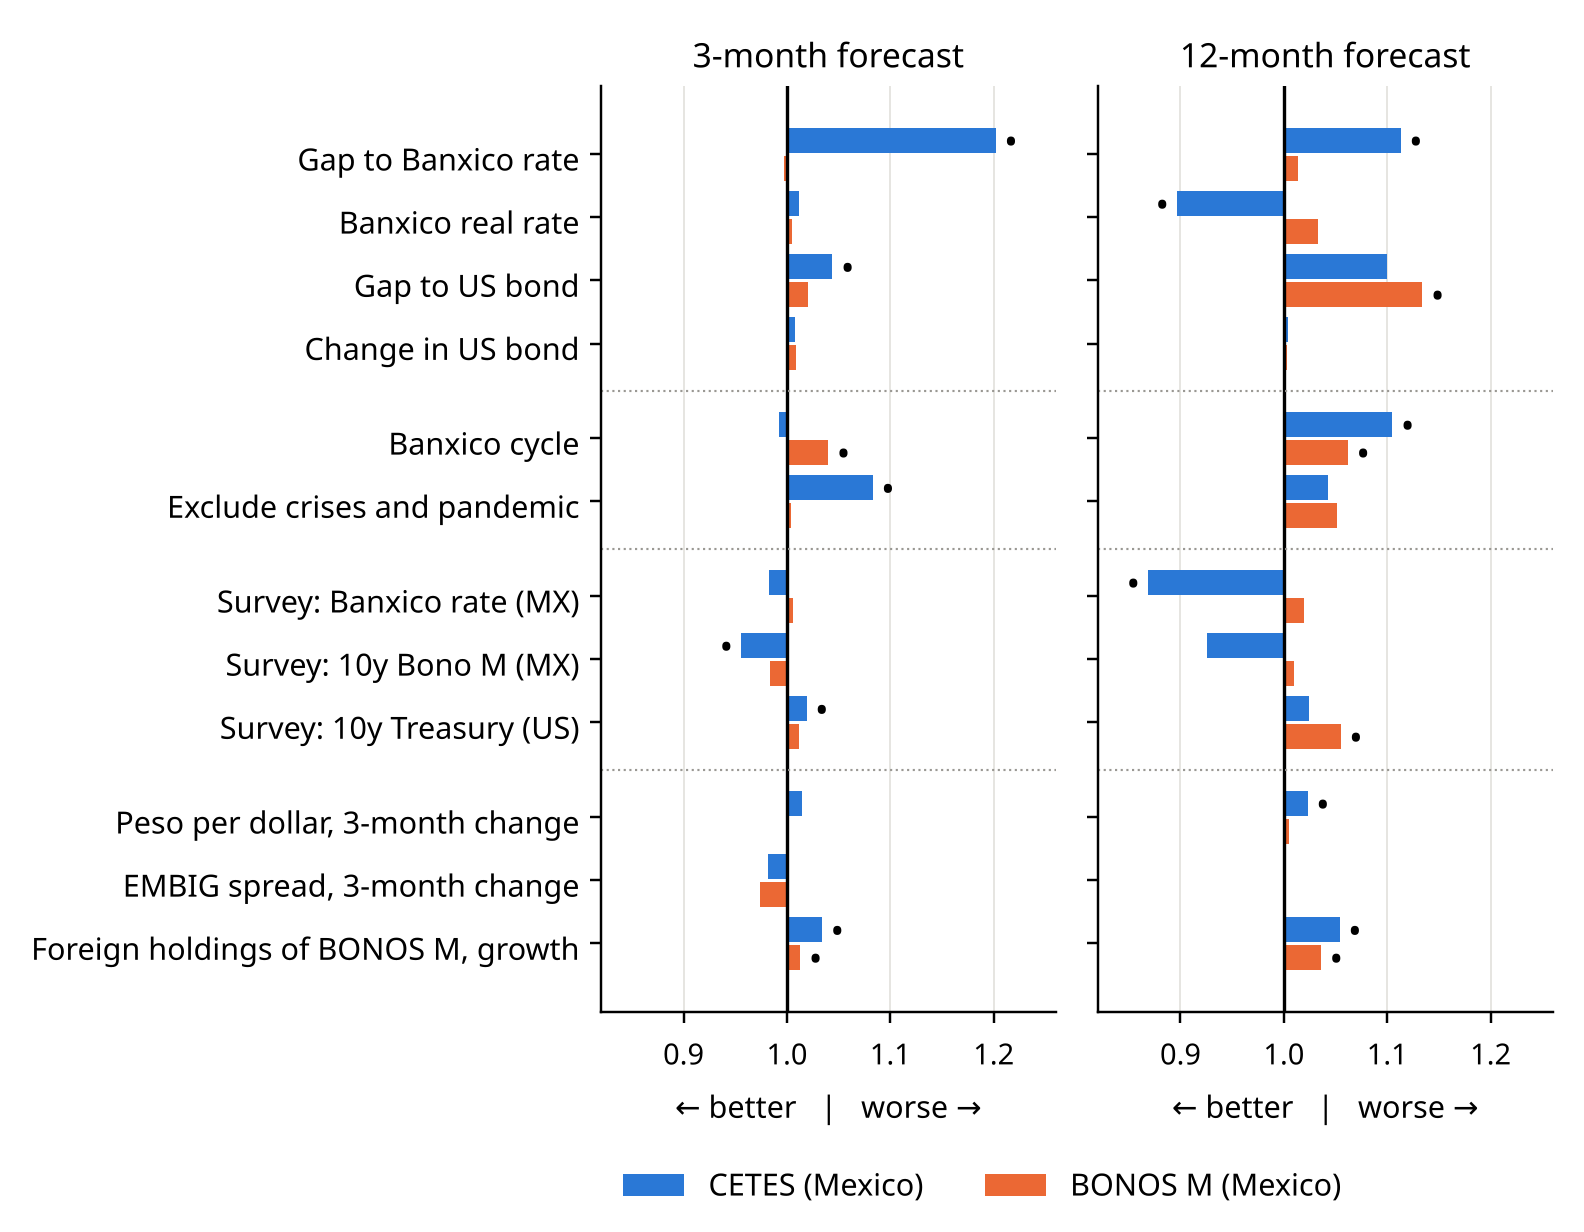

In [16]:
display(Image(f"{OUT}/fig5_external_events.png", width=560))

### Analysts' survey expectations

**Decision:** test the expectations published in Banxico's monthly Survey of Private Sector Economists (expected policy rate by quarter, from August 2010; expected 10-year Bono M by year, from July 2013) and in the Philadelphia Fed's Survey of Professional Forecasters (expected 10-year Treasury). Each forecast uses only the survey already published: Banxico's survey of month m is released early in month m+1, and the US survey in the middle of each quarter. See `survey_data.py` and `surveys.py`.

In [17]:
T6 = S.T6.copy()
T6["vs slope model"] = (T6.RMSE_vs_Slope - 1).map(lambda x: f"{x:+.0%}") + np.where(T6.p_vs_Slope < .05, "*", "")
T6["vs no change"] = (T6.RMSE_vs_RW - 1).map(lambda x: f"{x:+.0%}") + np.where(T6.p_vs_RW < .05, "*", "")
print("Change in error on the same forecast dates (* = significant at 95%)")
T6[T6.segment.isin(["CETES", "BONOS"])].pivot_table(index="model", columns=["segment", "h"], values=["vs slope model", "vs no change"], aggfunc="first")

Change in error on the same forecast dates (* = significant at 95%)


vs no change                      vs slope model                     
segment                   BONOS         CETES                 BONOS         CETES       
h                            3      12     3      12             3      12     3      12
model                                                                                   
Bono10Survey              +10%*    -5%    +6%   -9%*            +5%  -15%*  +41%*    +4%
PolicySurvey               +6%*    +8%  -19%*  -22%*            +2%    -4%    +7%   -12%
Slope+Bono10Survey          +3%  +11%*  -29%*  -23%*            -2%    +1%   -4%*    -7%
Slope+PolicySurvey         +4%*  +14%*  -26%*  -23%*            +1%    +2%    -2%  -13%*
Slope+SPF                  +5%*  +18%*  -23%*   -10%            +1%   +6%*   +2%*    +2%

In [18]:
# The no-estimation survey forecast for CETES one year ahead, by maturity and by half of the sample (forecast date)
RS = S.RS
def vs_rw(m, h, pls, sub=None):
    a = RS[(RS.model == m) & (RS.h == h) & RS.maturity.isin(pls)]
    mm = a.merge(R[(R.model == "RW") & (R.h == h)], on=["origin", "target", "maturity"], suffixes=("_1", "_2"))
    if sub == "2013-2019": mm = mm[mm.origin < "2020-01-01"]
    if sub == "2020-2026": mm = mm[mm.origin >= "2020-01-01"]
    r = np.sqrt((mm.err_1**2).mean() / (mm.err_2**2).mean()) - 1; _, p = C.dm_hln(mm.err_1.values, mm.err_2.values, h)
    return r, p
for c in CETES:
    r, p = vs_rw("PolicySurvey", 12, [c]); print(f"{c}: {r:+.0%} vs no change (p = {p:.3f})")
SV = {k: vs_rw("PolicySurvey", 12, CETES, k)[0] for k in ["2013-2019", "2020-2026"]}
print("CETES, by forecast date:", {k: f"{v:+.0%}" for k, v in SV.items()})

1m: -23% vs no change (p = 0.008)
3m: -23% vs no change (p = 0.007)
6m: -22% vs no change (p = 0.007)
12m: -21% vs no change (p = 0.008)
CETES, by forecast date: {'2013-2019': '-18%', '2020-2026': '-24%'}


### Market variables used for emerging markets

**Decision:** test the variables that the emerging-market literature adds to explain local bond rates: the EMBIG Mexico sovereign spread (level and 3-month change), the peso per dollar (monthly average, 1- and 3-month log change, because the daily rate is too noisy), the 3-month growth of foreign holdings of BONOS M, the long slope (10-year minus 12-month) and a Cochrane-Piazzesi-type factor built from five rates. Each enters the slope model alone, with the same method and forecast dates as the surveys. See `market_data.py` and `extra_predictors.py`.

**Result:** none beats "the rate does not change" for BONOS M. The exchange rate changes the error by less than 3% and its sign flips between 2013-2019 and 2020-2026; only the 3-month EMBIG change and the five-rate factor reduce the slope model's error.

In [19]:
T7 = X.T7[X.T7.period == "all"].copy()
T7["vs slope model"] = (T7.RMSE_vs_Slope - 1).map(lambda x: f"{x:+.0%}") + np.where(T7.p_vs_Slope < .05, "*", "")
T7["vs no change"] = (T7.RMSE_vs_RW - 1).map(lambda x: f"{x:+.0%}") + np.where(T7.p_vs_RW < .05, "*", "")
print("Change in error on the same forecast dates (* = significant at 95%)")
T7[T7.segment.isin(["CETES", "BONOS"])].pivot_table(index="model", columns=["segment", "h"], values=["vs slope model", "vs no change"], aggfunc="first")

Change in error on the same forecast dates (* = significant at 95%)


vs no change                      vs slope model                     
segment                BONOS         CETES                 BONOS         CETES       
h                         3      12     3      12             3      12     3      12
model                                                                                
CP-type                  -1%    +2%  -22%*    -7%           -5%*   -9%*    +3%    +6%
Slope+EMBIG             +7%*  +23%*  -13%*    +0%           +3%*  +10%*  +15%*  +14%*
Slope+LongSlope         +5%*  +17%*  -24%*  -13%*            +1%   +5%*   +1%*    -1%
Slope+ΔEMBIG             +1%  +12%*  -26%*   -12%            -3%    +0%    -2%    +0%
Slope+ΔFX1              +4%*  +12%*  -24%*   -11%            +1%    +0%    +1%    +1%
Slope+ΔFX3              +4%*  +13%*  -23%*   -10%            -0%    +0%    +2%   +2%*
Slope+ΔForeign          +5%*  +16%*  -22%*    -7%           +1%*   +4%*   +3%*   +5%*

In [20]:
# The exchange rate by half of the sample (forecast date): the sign flips
q = X.T7[X.T7.model.isin(["Slope+ΔFX1", "Slope+ΔFX3"]) & (X.T7.segment == "Curve")]
q.assign(vs_slope=(q.RMSE_vs_Slope - 1).map(lambda x: f"{x:+.1%}")).pivot_table(index=["model", "h"], columns="period", values="vs_slope", aggfunc="first")

period        2013-19 2020-26    all
model      h                        
Slope+ΔFX1 3    +3.6%   -1.6%  +0.6%
           12   +2.4%   -0.6%  +0.8%
Slope+ΔFX3 3    +4.8%   -2.7%  +0.5%
           12   +4.1%   -0.6%  +1.6%

## 6. Traceability: figures in the brief versus this notebook

In [21]:
def r2(m, h, pls): return seg_ratio(m, h, pls)[0]
def xm(m, h, seg): return X.T7[(X.T7.period == "all") & (X.T7.model == m) & (X.T7.h == h) & (X.T7.segment == seg)].RMSE_vs_Slope.iloc[0] - 1
def ext(m, h, seg):
    T = T4 if m.startswith("Ext") else T5
    q = T[(T.h == h) & (T.model == m) & (T.segment == seg)]
    if "excl_pandemic" in q: q = q[q.excl_pandemic == False]
    return q.RMSE_vs_Slope.iloc[0] - 1
hp = pd.read_csv(f"{OUT}/t1_pca_by_horizon.csv").set_index("horizon_months")
checks = [
 ("Three movements explain, 1-month changes", "78%", hp.loc[1, "cum3"], "pct"),
 ("Three movements explain, 3-month changes", "91%", hp.loc[3, "cum3"], "pct"),
 ("Three movements explain, 12-month changes", "99%", hp.loc[12, "cum3"], "pct"),
 ("Level / slope / curvature share, 12-month changes", "86% / 10% / 2%", "/".join(f"{x:.0%}" for x in hp.loc[12, ["PC1", "PC2", "PC3"]]), "txt"),
 ("Level share 2006-2015", "63%", a[0], "pct"), ("Slope share 2006-2015", "30%", a[1], "pct"),
 ("Level share 2016-2026", "91%", b[0], "pct"), ("Slope share 2016-2026", "7%", b[1], "pct"),
 ("Level share by period (2007-11, 12-16, 17-21, 22-26)", "77% / 51% / 91% / 93%", " / ".join(f"{x:.0%}" for x in PERIODS["level share"]), "txt"),
 ("Slope vs Banxico rate by period", "-0.92 / -0.82 / -0.91 / -0.94", " / ".join(f"{x:.2f}" for x in PERIODS.iloc[:, 1]), "txt"),
 ("Level vs US bond by period", "-0.10 / 0.71 / 0.66 / 0.46", " / ".join(f"{x:.2f}" for x in PERIODS.iloc[:, 2]), "txt"),
 ("Months with negative fitted slope", "43", int(inv.sum()), "txt"),
 ("Months with a level change above 1.1 points", "4", int((dL > 1.1).sum()), "txt"),
 ("Largest 12-month rise: 3-year bond / 28-day CETE / 30-year bond", "3.8 / 2.3 / 0.9", f"{d12.loc[j, '3y']:.1f} / {d12.loc[j, '1m']:.1f} / {d12.loc[j, '30y']:.1f}", "txt"),
 ("Slope model vs no change, CETES 3 months", "-25% (0.75)", r2("Slope", 3, CETES) - 1, "chg"),
 ("Slope model vs no change, 28-day CETE 3 months", "-35%", ratio.loc[(3, "Slope"), "1m"] - 1, "chg"),
 ("Slope model vs no change, 364-day CETE 3 months", "-12%", ratio.loc[(3, "Slope"), "12m"] - 1, "chg"),
 ("Nine-rate VAR vs no change, CETES 3 months", "0.72", r2("VAR1", 3, CETES), "num"),
 ("Principal components + AR vs no change, BONOS M 3 months", "1.42", r2("PCA3-AR1", 3, BONOS), "num"),
 ("CETES at 12 months, forecasts made in 2013-2019 / 2020-2026", "+6% / -22%", f"{SUBP['2013-2019']:+.0%} / {SUBP['2020-2026']:+.0%}", "txt"),
 ("Diebold-Li / principal components + AR vs AR, whole curve 3 months", "+9% / +24%", " / ".join(f"{Q3[(Q3.h == 3) & (Q3.with_pattern == m) & (Q3.without_pattern == 'AR1')].RMSE_ratio.iloc[0]-1:+.0%}" for m in ["DNS-AR1", "PCA3-AR1"]), "txt"),
 ("Slope vs nine-rate VAR, whole curve 3 / 12 months", "+3% / -1%", " / ".join(f"{Q3[(Q3.h == h) & (Q3.with_pattern == 'Slope') & (Q3.without_pattern == 'VAR1')].RMSE_ratio.iloc[0]-1:+.0%}" for h in [3, 12]), "txt"),
 ("Change of direction windows (two definitions)", "-18%", gain(c3[np.sign(c3.dpol) * np.sign(c3.dprev) < 0]), "chg"),
 ("Gain when Banxico moved > 0.5 points", "-35%", gain(c3[c3.dpol.abs() > .5]), "chg"),
 ("Loss when Banxico held its rate", "+46%", gain(c3[c3.dpol == 0]), "chg"),
 ("Slope vs each rate's history (AR), whole curve 3 / 12 months", "-12% / -10%", " / ".join(f"{Q3[(Q3.h == h) & (Q3.with_pattern == 'Slope') & (Q3.without_pattern == 'AR1')].RMSE_ratio.iloc[0]-1:+.0%}" for h in [3, 12]), "txt"),
 ("Diebold-Li vs AR, whole curve 3 / 12 months", "+9% / +7%", " / ".join(f"{Q3[(Q3.h == h) & (Q3.with_pattern == 'DNS-AR1') & (Q3.without_pattern == 'AR1')].RMSE_ratio.iloc[0]-1:+.0%}" for h in [3, 12]), "txt"),
 ("Real rate vs slope model, CETES 12 months", "-10%", ext("Ext:Slope+RealRate", 12, "CETES"), "chg"),
 ("US bond gap vs slope model, CETES 3 / 12 months", "+4% / +10%", f"{ext('Ext:Slope+SpreadUST', 3, 'CETES'):+.0%} / {ext('Ext:Slope+SpreadUST', 12, 'CETES'):+.0%}", "txt"),
 ("Banxico cycle vs slope model, CETES 3 / 12 months", "-1% / +10%", f"{ext('Slope+Cycle', 3, 'CETES'):+.0%} / {ext('Slope+Cycle', 12, 'CETES'):+.0%}", "txt"),
 ("Survey forecast (Banxico rate) vs no change, CETES 12 months", "-22%", vs_rw("PolicySurvey", 12, CETES)[0], "chg"),
 ("Same, forecasts made in 2013-2019 / 2020-2026", "-18% / -24%", f"{SV['2013-2019']:+.0%} / {SV['2020-2026']:+.0%}", "txt"),
 ("Slope + Banxico-rate survey vs slope model, CETES 3 / 12 months", "-2% / -13%", " / ".join(f"{S.T6[(S.T6.h == h) & (S.T6.model == 'Slope+PolicySurvey') & (S.T6.segment == 'CETES')].RMSE_vs_Slope.iloc[0]-1:+.0%}" for h in [3, 12]), "txt"),
 ("Survey forecast (10-year Bono M) vs no change, BONOS M 12 months", "-5%", vs_rw("Bono10Survey", 12, BONOS)[0], "chg"),
 ("Slope + US survey vs slope model, BONOS M 12 months", "+6%", S.T6[(S.T6.h == 12) & (S.T6.model == 'Slope+SPF') & (S.T6.segment == 'BONOS')].RMSE_vs_Slope.iloc[0] - 1, "chg"),
 ("Peso per dollar change vs slope model, largest effect (any segment, 3 or 12 months)", "<3%", "<3%" if (X.T7[(X.T7.period == "all") & X.T7.model.isin(["Slope+ΔFX1", "Slope+ΔFX3"])].RMSE_vs_Slope - 1).abs().max() < .03 else "no", "txt"),
 ("3-month EMBIG change vs slope model, whole curve 3 months", "-2%", xm("Slope+ΔEMBIG", 3, "Curve"), "chg"),
 ("Five-rate factor vs slope model, BONOS M 3 / 12 months", "-5% / -9%", f"{xm('CP-type', 3, 'BONOS'):+.0%} / {xm('CP-type', 12, 'BONOS'):+.0%}", "txt"),
 ("Excluding crises vs slope model, CETES 3 / 12 months", "+8% / +4%", f"{ext('Slope excl. episodes', 3, 'CETES'):+.0%} / {ext('Slope excl. episodes', 12, 'CETES'):+.0%}", "txt"),
]
fmt = {"pct": lambda x: f"{x:.0%}", "chg": lambda x: f"{x:+.0%}", "num": lambda x: f"{x:.2f}", "txt": str}
TRACE = pd.DataFrame([(k, b_, fmt[f](c_)) for k, b_, c_, f in checks], columns=["claim", "in the brief", "computed here"])
TRACE["match"] = [b_.replace("−", "-").replace(" ", "").split("(")[0] == c_.replace(" ", "") for b_, c_ in zip(TRACE["in the brief"], TRACE["computed here"])]
pd.set_option("display.max_colwidth", 80); TRACE

,claim,in the brief,computed here,match
0,"Three movements explain, 1-month changes",78%,78%,True
1,"Three movements explain, 3-month changes",91%,91%,True
2,"Three movements explain, 12-month changes",99%,99%,True
3,"Level / slope / curvature share, 12-month changes",86% / 10% / 2%,86%/10%/2%,True
4,Level share 2006-2015,63%,63%,True
5,Slope share 2006-2015,30%,30%,True
6,Level share 2016-2026,91%,91%,True
7,Slope share 2016-2026,7%,7%,True
8,"Level share by period (2007-11, 12-16, 17-21, 22-26)",77% / 51% / 91% / 93%,77% / 51% / 91% / 93%,True
9,Slope vs Banxico rate by period,-0.92 / -0.82 / -0.91 / -0.94,-0.92 / -0.82 / -0.91 / -0.94,True


## References

Works cited in the brief.

- Aguilar-Argaez, A., Diego-Fernández, M., Elizondo, R. and Roldán-Peña, J. (2020). *Term premium dynamics and its determinants: the Mexican case*. Working Paper 2020-18, Banco de México. Published in *Latin American Economic Review*, 32 (2023), 1–47. https://doi.org/10.60758/laer.v32.105
- Altavilla, C., Giacomini, R. and Ragusa, G. (2017). Anchoring the yield curve using survey expectations. *Journal of Applied Econometrics*, 32(6), 1055–1068. https://doi.org/10.1002/jae.2588
- Arslanalp, S. and Tsuda, T. (2014). *Tracking global demand for emerging market sovereign debt*. IMF Working Paper 14/39.
- Banco de México (2022). Traspaso de la tasa de referencia de México sobre las tasas de interés a distintos plazos. *Informe Trimestral abril–junio 2022*, Recuadro 6.
- Banco de México (2025). Co-movimiento entre las tasas de interés de mediano y largo plazo internacionales. *Informe Trimestral julio–septiembre 2025*, Recuadro 5.
- Campbell, J. Y. and Shiller, R. J. (1991). Yield spreads and interest rate movements: a bird's eye view. *Review of Economic Studies*, 58(3), 495–514.
- Clark, T. E. and West, K. D. (2007). Approximately normal tests for equal predictive accuracy in nested models. *Journal of Econometrics*, 138(1), 291–311.
- Cochrane, J. H. and Piazzesi, M. (2005). Bond risk premia. *American Economic Review*, 95(1), 138–160.
- Cortés Espada, J. F. and Ramos-Francia, M. (2008). *An affine model of the term structure of interest rates in Mexico*. Working Paper 2008-09, Banco de México.
- Cortés Espada, J. F., Ramos-Francia, M. and Torres García, A. (2008). *An empirical analysis of the Mexican term structure of interest rates*. Working Paper 2008-07, Banco de México.
- Diebold, F. X. and Li, C. (2006). Forecasting the term structure of government bond yields. *Journal of Econometrics*, 130(2), 337–364.
- Diebold, F. X. and Mariano, R. S. (1995). Comparing predictive accuracy. *Journal of Business & Economic Statistics*, 13(3), 253–263.
- Duffee, G. R. (2002). Term premia and interest rate forecasts in affine models. *Journal of Finance*, 57(1), 405–443.
- Eichengreen, B. and Gupta, P. (2015). Tapering talk: the impact of expectations of reduced Federal Reserve security purchases on emerging markets. *Emerging Markets Review*, 25, 1–15.
- Elizondo, R. (2013). *Pronósticos de la estructura temporal de las tasas de interés en México utilizando un modelo afín*. Working Paper 2013-03, Banco de México.
- Fama, E. F. and Bliss, R. R. (1987). The information in long-maturity forward rates. *American Economic Review*, 77(4), 680–692.
- Harvey, D., Leybourne, S. and Newbold, P. (1997). Testing the equality of prediction mean squared errors. *International Journal of Forecasting*, 13(2), 281–291.
- Hördahl, P. and Shim, I. (2020). *EME bond portfolio flows and long-term interest rates during the Covid-19 pandemic*. BIS Bulletin 18, Bank for International Settlements.
- Ibarra-Ramírez, R. (2021). *The yield curve as a predictor of economic activity in Mexico: the role of the term premium*. Working Paper 2021-07, Banco de México.
- Kang, J. T. (2026). *Yield curve prediction with machine learning: forecasting approaches and the role of macroeconomic predictors*. arXiv:2608.07536.
- Litterman, R. and Scheinkman, J. (1991). Common factors affecting bond returns. *Journal of Fixed Income*, 1(1), 54–61.
- Marcellino, M., Stock, J. H. and Watson, M. W. (2006). A comparison of direct and iterated multistep AR methods for forecasting macroeconomic time series. *Journal of Econometrics*, 135(1–2), 499–526.
- Nelson, C. R. and Siegel, A. F. (1987). Parsimonious modeling of yield curves. *Journal of Business*, 60(4), 473–489.
- Pesaran, M. H. and Timmermann, A. (2007). Selection of estimation window in the presence of breaks. *Journal of Econometrics*, 137(1), 134–161.
- Uribe, M. and Yue, V. Z. (2006). Country spreads and emerging countries: who drives whom? *Journal of International Economics*, 69(1), 6–36.

### Data sources

- Primary-auction rates: monthly averages from Banco de México, checked against Banco de México's Economic Information System (SIE).
- Banxico policy rate, INPC inflation (SP1), analysts' survey (tables CR168 and CR189) and foreign holdings of BONOS M (CA175): Banco de México, SIE.
- US Treasury yields (DGS10, DGS3MO) and the peso per dollar (EXMXUS): Federal Reserve Bank of St. Louis, FRED.
- US Survey of Professional Forecasters: Federal Reserve Bank of Philadelphia.
- EMBIG Mexico spread (J.P. Morgan), series PN01135XM: Banco Central de Reserva del Perú.